## 08B Evaluation: Additional Analysis

#### Purpose
08a evaluated the models as classifiers. This notebook checks what a confusion matrix cannot show, and what the business needs:
- **The probabilities themselves:** log loss, Brier score, calibration and expected vs actual counts. The models are used for expected claims, expected lapses and pricing, so a 2% must mean 2%.
- **Where the models hold and where they fail:** by segment (state, flood zone, storm during the term), by year, and for lapse, over the life of a policy (**cohort survival analysis**).
- **How we would monitor them in production:** drift and alert rules.

It reads the predictions saved by **08a**, so the evaluation split is scored only once.

#### Steps:
0. Settings, and the predictions from 08a
1. **Claim model:** probability check, calibration, calibration by segment, stability over time, simulated monitoring
2. **Lapse model:** the same, plus the cohort survival analysis (retention of new business)
3. Appendix: bootstrap of the gains, policy history and linkage
4. Conclusions and save

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-17

### Section 0. Load the libraries and working directory
Use the same setup cell as notebook 02 (repo root, data folders, reports folder). The shared evaluation code is in `src/evaluation.py`.

#### 0.1 Imports and paths

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs
from src.db import connect
from src import evaluation as ev
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates stay readable

ensure_dirs()

#### 0.2 Settings and the holdout switch
`EVAL_SPLIT` decides which out-of-time period is evaluated:

| `EVAL_SPLIT` | Years evaluated | When |
|---|---|---|
| `"test"` | OOT1, 2021–2022 | Dry run: as often as we like, while 07a/07b are being built |
| `"valid"` | OOT2, 2023 – Aug 2024 | **Once**, after 07a and 07b are final |

**08a and 08b must use the same value**: 08a scores the split and saves the predictions, 08b reads them (and stops if they were made for another split). In the dry run, nothing after 2022 is read. Every saved file carries the name of the split (`eval_test_…` or `eval_valid_…`), so the dry run never overwrites the final results.

We also rebuild the model registry and the naive benchmarks: the stability, cohort and monitoring steps score samples of other years.

In [2]:
# Step 0.2 Settings, the predictions saved by 08a, the model registry and the naive benchmarks

EVAL_SPLIT = "valid"        # change to "valid" ONCE, in 08a and 08b, after notebooks 07a and 07b are final
assert EVAL_SPLIT in ("test", "valid")
EVAL_NAME = ev.EVAL_NAMES[EVAL_SPLIT]
LAST_YEAR = 2022 if EVAL_SPLIT == "test" else 2024     # later years stay closed in the dry run
OUT = f"eval_{EVAL_SPLIT}"                             # prefix of every saved file
SEED = 42
MODEL_DIR, PRED_DIR = PROCESSED / "models", PROCESSED / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
KINDS = pd.read_csv(DOCS / "feature_plan.csv").set_index("feature")["kind"].to_dict()   # num / cat / flag per feature

con = connect(db_path=None, memory_limit="6GB")
con.execute(f"CREATE OR REPLACE VIEW feats AS SELECT * FROM read_parquet('{PROCESSED / 'features.parquet'}')")

# The primary model of each target (shown in the charts): None = the advanced model with the lowest test log loss
# in its run record, otherwise the baseline. Set a model name, e.g. {"lapse": "lapse_rf"}, to choose it yourself.
PRIMARY_CHOICE = {"claim": None, "lapse": None}

# The models of each target, the primary model, and the two naive benchmarks rebuilt from the training split
registry, PRIMARY, base_rate, COLS = {}, {}, {}, {}
for kind in ev.TARGETS:
    registry[kind] = ev.load_registry(kind, MODEL_DIR, REPORTS)
    PRIMARY[kind] = ev.primary_model(registry[kind], PRIMARY_CHOICE.get(kind))
    base_rate[kind] = ev.build_benchmarks(con, kind)
    COLS[kind] = ev.model_columns(registry[kind])      # probability column of each model, in table order

N_BOOT = 200               # bootstrap samples (Step 3.1)
STABILITY_ROWS = 200_000   # rows per year (Steps 1.4, 2.4)
REFERENCE_ROWS = 100_000   # training rows per calendar quarter, the monitoring reference (Steps 1.5, 2.7)
QUARTER_ROWS = 100_000     # rows per quarter (Steps 1.5, 2.7)
COHORT_KEYS = 30_000       # new-business policies followed per cohort (Step 2.5)

run_08a = json.loads((REPORTS / f"{OUT}_08a_run.json").read_text())
assert run_08a["eval_split"] == EVAL_SPLIT, "08a scored another split: run 08a with the same EVAL_SPLIT first"
pred = {kind: pd.read_parquet(PRED_DIR / f"{OUT}_{kind}_predictions.parquet") for kind in ev.TARGETS}
for kind, p in pred.items():
    missing = set(COLS[kind].values()) - set(p.columns)
    assert not missing, f"{kind}: 08a has no predictions for {missing}: re-run 08a"
    print(f"{kind}: {len(p):,} rows of {EVAL_NAME} from 08a (scored {run_08a['scored_at']}); primary model {PRIMARY[kind]}")
QUARTERS = [(y, q) for y in range(2021, LAST_YEAR + 1) for q in range(1, 5) if not (y == 2024 and q == 4)]

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


claim: 5,724,790 rows of OOT2 (validation, 2023 - Aug 2024) from 08a (scored 2026-11-18T00:43:43); primary model claim_xgb
lapse: 5,621,274 rows of OOT2 (validation, 2023 - Aug 2024) from 08a (scored 2026-11-18T00:43:43); primary model lapse_rf


### Section 1. Claim model

#### 1.1 Probability check
For every model and both benchmarks, overall and for each year. Let $y_i \in \{0,1\}$ be the outcome and $p_i$ the predicted probability.

$$\text{LogLoss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big] \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n}(p_i - y_i)^2$$

$$\text{Skill} = 1 - \frac{\text{score}_{\text{model}}}{\text{score}_{\text{base rate}}} \qquad \text{A/E} = \frac{\sum_i y_i}{\sum_i p_i}$$

- **Log loss** and **Brier score**: lower is better; both are proper scoring rules (a model gets its best score only by giving the true probabilities). Log loss is also what we tuned on in 06a/06b.
- **Skill**: the improvement over giving everyone the training rate, on the same rows (0% = no better than the base rate).
- **A/E** (actual ÷ expected): 1 = the model expects as many claims as happened; above 1 = it under-predicts.

In [3]:
# Step 1.1 Claim: log loss, Brier, skill and A/E, overall and per year
p = pred["claim"]
prob_claim = ev.probability_table([(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]], COLS["claim"])
prob_claim.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                          "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}",
                          "brier_skill": "{:+.2%}"})

,scope,model,rows,events,actual_rate,predicted_rate,a_to_e,log_loss,brier,log_loss_skill,brier_skill
0,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,724,790","89,516",1.564%,1.301%,1.202,0.08078,0.015399,+0.00%,+0.00%
1,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,724,790","89,516",1.564%,1.337%,1.170,0.07816,0.015325,+3.24%,+0.48%
2,"OOT2 (validation, 2023 - Aug 2024)",claim_baseline_logreg,"5,724,790","89,516",1.564%,1.719%,0.910,0.07836,0.015321,+3.00%,+0.51%
3,"OOT2 (validation, 2023 - Aug 2024)",claim_lgbm,"5,724,790","89,516",1.564%,1.332%,1.174,0.07991,0.015794,+1.08%,-2.57%
4,"OOT2 (validation, 2023 - Aug 2024)",claim_rf,"5,724,790","89,516",1.564%,1.708%,0.916,0.07613,0.015338,+5.76%,+0.40%
5,"OOT2 (validation, 2023 - Aug 2024)",claim_xgb,"5,724,790","89,516",1.564%,1.091%,1.433,0.08227,0.015763,-1.84%,-2.36%
6,2023,base rate,"3,443,343","33,302",0.967%,1.301%,0.743,0.05496,0.009589,+0.00%,+0.00%
7,2023,segment rate,"3,443,343","33,302",0.967%,1.332%,0.726,0.05340,0.009556,+2.84%,+0.35%
8,2023,claim_baseline_logreg,"3,443,343","33,302",0.967%,1.682%,0.575,0.05507,0.009626,-0.19%,-0.38%
9,2023,claim_lgbm,"3,443,343","33,302",0.967%,1.311%,0.738,0.05482,0.010089,+0.26%,-5.21%


#### 1.2 Calibration
We sort the rows by each model's predicted probability, cut them into 10 equal groups (deciles) and compare the mean prediction $\bar p_d$ with the actual rate $\bar y_d$ in each.

- **Expected calibration error:** $\text{ECE} = \sum_{d}\frac{n_d}{n}\,|\bar{y}_d - \bar{p}_d|$, also shown as a share of the actual rate.
- **Calibration intercept and slope:** a logistic regression of the outcome on the model's own log-odds, $\text{logit}\,P(y_i=1) = a + b\,\text{logit}(p_i)$. $b = 1, a = 0$: perfect; $b < 1$: probabilities **too extreme** (overfitting); $b > 1$: **too timid**; $a \neq 0$ with $b \approx 1$: the overall level is off.
- **Expected vs actual:** the sum of the probabilities is the number of claims the model expects, $E[\text{claims}] = \sum_i p_i$, the most direct business check.

We do not use the Hosmer–Lemeshow test: with millions of rows it rejects even a tiny, harmless miscalibration.

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

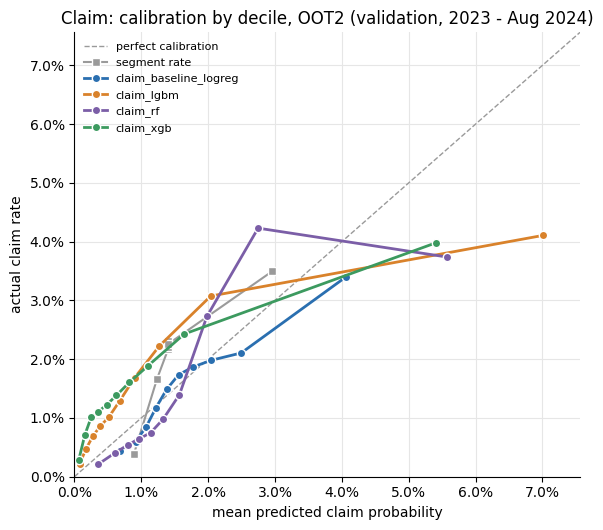

,actual,expected: base rate,expected: segment rate,expected: claim_baseline_logreg,expected: claim_lgbm,expected: claim_rf,expected: claim_xgb
period_year,,,,,,,
2023,"33,302","44,809","45,878","57,911","45,151","56,607","36,959"
2024,"56,214","29,689","30,636","40,478","31,089","41,169","25,525"
all,"89,516","74,498","76,514","98,389","76,240","97,775","62,484"


,rows,events,predicted,actual,actual_to_predicted
p_claim_xgb,,,,,
10,"572,479","22,774",5.402%,3.978%,0.74
9,"572,479","13,903",1.643%,2.429%,1.48
8,"572,479","10,833",1.106%,1.892%,1.71
7,"572,479","9,183",0.821%,1.604%,1.95
6,"572,479","7,917",0.628%,1.383%,2.20
5,"572,479","6,987",0.480%,1.220%,2.54
4,"572,479","6,351",0.359%,1.109%,3.09
3,"572,479","5,831",0.253%,1.019%,4.02
2,"572,479","4,090",0.157%,0.714%,4.56


,model,a_to_e,ece,ece_pct_of_rate,intercept_a,slope_b
0,segment rate,1.170,0.00633,40.5%,+1.743,1.382
1,claim_baseline_logreg,0.910,0.00231,14.8%,-0.231,0.970
2,claim_lgbm,1.174,0.00811,51.9%,-1.620,0.541
3,claim_rf,0.916,0.00590,37.7%,-0.222,0.967
4,claim_xgb,1.433,0.00757,48.4%,-1.808,0.479


In [4]:
# Step 1.2 Claim: calibration by decile, ECE, intercept and slope, and expected vs actual per year
calib_claim, deciles_claim = ev.calibration_summary(pred["claim"], COLS["claim"], seed=SEED)
fig, ax = plt.subplots(figsize=(6, 5.4))
ev.plot_calibration(ax, deciles_claim, f"Claim: calibration by decile, {EVAL_NAME}", "claim")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_calibration.png", dpi=150)
plt.show()

p = pred["claim"]
expected_claim = p.groupby("period_year").agg(actual=("y", "sum"), **{f"expected: {n}": (c, "sum") for n, c in COLS["claim"].items()})
expected_claim.loc["all"] = expected_claim.sum()
display(expected_claim.style.format("{:,.0f}"))
display(deciles_claim[PRIMARY["claim"]].sort_index(ascending=False).style.format(
    {"rows": "{:,}", "events": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}", "actual_to_predicted": "{:.2f}"}))
calib_claim.style.format({"a_to_e": "{:.3f}", "ece": "{:.5f}", "ece_pct_of_rate": "{:.1%}", "intercept_a": "{:+.3f}", "slope_b": "{:.3f}"})

#### 1.3 Calibration by segment
A model can be right on average and wrong for whole groups. For each segment we show the actual rate, the **A/E** of each model and the log-loss skill. The chart shows the A/E of the primary model with a 95% interval from the number of claims (Poisson approximation): $\text{A/E} \times \big(1 \pm 1.96/\sqrt{\text{actual claims}}\big)$; the shaded band is 0.8–1.2, the "watch" band of the monitoring rules.

**Storm during the term** splits the rows by the strongest IBTrACS wind at the property during the term (an outcome-period measure, used only here). We expect the claim model to **under-predict where a storm hit and over-predict where none did**: no model known at the start of a term can know where the next storm will land. What matters is that the two balance out over the portfolio.

In [5]:
# Step 1.3 (setup) The segments used for both targets
def top_states(frame, n=10):
    keep = frame["state"].value_counts().index[:n]
    return frame["state"].where(frame["state"].isin(keep), "other states")

SEGMENTS = {"state (largest 10)": top_states, "flood zone group": lambda f: f["zone_group"],
            "new business": lambda f: f["new_business"].map({1: "new business", 0: "renewal"}),
            "mandatory purchase": lambda f: f["mandatory_purchase"].map({1: "mandatory", 0: "voluntary"}),
            "storm during the term": lambda f: f["storm_in_term"]}

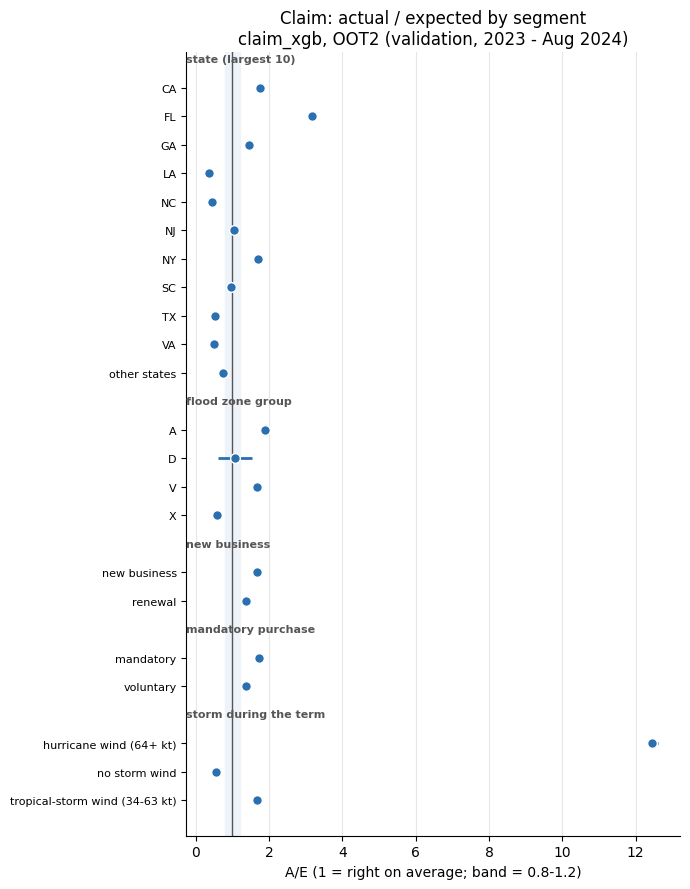

state (largest 10)


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,CA,base rate,"260,918",787,0.302%,0.232,+0.00%
1,CA,segment rate,"260,918",787,0.302%,0.239,+1.81%
2,CA,claim_baseline_logreg,"260,918",787,0.302%,0.302,+10.19%
3,CA,claim_lgbm,"260,918",787,0.302%,1.453,+26.24%
4,CA,claim_rf,"260,918",787,0.302%,0.633,+25.65%
5,CA,claim_xgb,"260,918",787,0.302%,1.766,+25.15%
6,FL,base rate,"1,708,334","62,116",3.636%,2.794,+0.00%
7,FL,segment rate,"1,708,334","62,116",3.636%,2.752,+3.97%
8,FL,claim_baseline_logreg,"1,708,334","62,116",3.636%,2.076,+6.61%
9,FL,claim_lgbm,"1,708,334","62,116",3.636%,2.500,+1.42%


flood zone group


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,A,base rate,"3,033,296","74,213",2.447%,1.880,+0.00%
1,A,segment rate,"3,033,296","74,213",2.447%,1.545,+2.14%
2,A,claim_baseline_logreg,"3,033,296","74,213",2.447%,1.323,+4.18%
3,A,claim_lgbm,"3,033,296","74,213",2.447%,1.505,-0.05%
4,A,claim_rf,"3,033,296","74,213",2.447%,1.229,+6.83%
5,A,claim_xgb,"3,033,296","74,213",2.447%,1.883,-4.24%
6,D,base rate,"2,515",21,0.835%,0.642,+0.00%
7,D,segment rate,"2,515",21,0.835%,0.759,+5.14%
8,D,claim_baseline_logreg,"2,515",21,0.835%,0.392,-9.73%
9,D,claim_lgbm,"2,515",21,0.835%,0.736,-3.89%


new business


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,new business,base rate,"901,243","16,389",1.818%,1.397,+0.00%
1,new business,segment rate,"901,243","16,389",1.818%,1.477,+1.71%
2,new business,claim_baseline_logreg,"901,243","16,389",1.818%,0.990,-0.15%
3,new business,claim_lgbm,"901,243","16,389",1.818%,1.437,+0.02%
4,new business,claim_rf,"901,243","16,389",1.818%,1.102,+5.63%
5,new business,claim_xgb,"901,243","16,389",1.818%,1.682,-3.86%
6,renewal,base rate,"4,823,547","73,127",1.516%,1.165,+0.00%
7,renewal,segment rate,"4,823,547","73,127",1.516%,1.118,+3.58%
8,renewal,claim_baseline_logreg,"4,823,547","73,127",1.516%,0.894,+3.69%
9,renewal,claim_lgbm,"4,823,547","73,127",1.516%,1.128,+1.32%


mandatory purchase


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,mandatory,base rate,"749,543","16,092",2.147%,1.650,+0.00%
1,mandatory,segment rate,"749,543","16,092",2.147%,1.444,+3.05%
2,mandatory,claim_baseline_logreg,"749,543","16,092",2.147%,1.200,+3.98%
3,mandatory,claim_lgbm,"749,543","16,092",2.147%,1.430,+1.59%
4,mandatory,claim_rf,"749,543","16,092",2.147%,1.151,+7.69%
5,mandatory,claim_xgb,"749,543","16,092",2.147%,1.717,-0.82%
6,voluntary,base rate,"4,975,247","73,424",1.476%,1.134,+0.00%
7,voluntary,segment rate,"4,975,247","73,424",1.476%,1.123,+3.28%
8,voluntary,claim_baseline_logreg,"4,975,247","73,424",1.476%,0.864,+2.80%
9,voluntary,claim_lgbm,"4,975,247","73,424",1.476%,1.130,+0.98%


storm during the term


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,hurricane wind (64+ kt),base rate,"282,947","27,602",9.755%,7.496,+0.00%
1,hurricane wind (64+ kt),segment rate,"282,947","27,602",9.755%,8.023,+3.29%
2,hurricane wind (64+ kt),claim_baseline_logreg,"282,947","27,602",9.755%,5.491,+7.08%
3,hurricane wind (64+ kt),claim_lgbm,"282,947","27,602",9.755%,10.891,+2.35%
4,hurricane wind (64+ kt),claim_rf,"282,947","27,602",9.755%,6.991,+11.38%
5,hurricane wind (64+ kt),claim_xgb,"282,947","27,602",9.755%,12.449,-7.33%
6,no storm wind,base rate,"3,379,023","19,912",0.589%,0.453,+0.00%
7,no storm wind,segment rate,"3,379,023","19,912",0.589%,0.433,+1.41%
8,no storm wind,claim_baseline_logreg,"3,379,023","19,912",0.589%,0.352,-4.28%
9,no storm wind,claim_lgbm,"3,379,023","19,912",0.589%,0.431,-1.18%


In [6]:
# Step 1.3 Claim: A/E and skill by segment, for every model; chart for the primary model
seg_claim = {label: ev.segment_table(pred["claim"], COLS["claim"], key(pred["claim"])) for label, key in SEGMENTS.items()}
fig, ax = plt.subplots(figsize=(7, 9))
ev.plot_ae_by_segment(ax, seg_claim, PRIMARY["claim"], f"Claim: actual / expected by segment\n{PRIMARY['claim']}, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_segments.png", dpi=150)
plt.show()
for label, t in seg_claim.items():
    print(label)
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss_skill": "{:+.2%}"}))

#### 1.4 Stability over time
We score a random sample of every year from 2014 with the frozen models and follow the A/E and the log-loss skill: **in-sample** (2014–2020, the years the models learned from), **OOT1** (2021–2022) and **OOT2** (2023 – Aug 2024, final run only).

Claims are driven by storms, so the claim A/E swings from year to year even for a good model: high in a big storm year, low in a calm one. What we look for is a **trend** (A/E drifting away from 1) or skill falling below 0 in the out-of-time years.

scored 11 years in 2.4 min


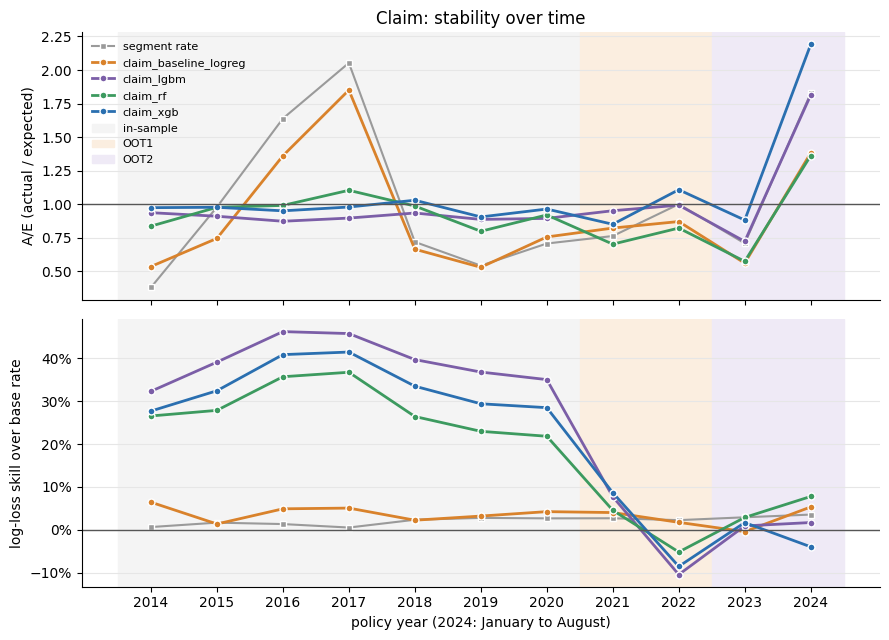

a_to_e                                                      \
model          base rate claim_baseline_logreg claim_lgbm claim_rf claim_xgb   
year period                                                                    
2014 in-sample     0.381                 0.536      0.937    0.837     0.975   
2015 in-sample     0.978                 0.746      0.911    0.977     0.978   
2016 in-sample     1.631                 1.361      0.873    0.991     0.951   
2017 in-sample     2.048                 1.851      0.897    1.104     0.979   
2018 in-sample     0.725                 0.665      0.935    0.987      1.03   
2019 in-sample     0.545                  0.53      0.887    0.799     0.906   
2020 in-sample     0.706                 0.756      0.895     0.92     0.964   
2021 OOT1          0.765                 0.823      0.952    0.703     0.851   
2022 OOT1          1.011                 0.871      0.993    0.823     1.108   
2023 OOT2          0.724                 0.561      0.723    0.575     0.882   
2024 OOT2          1.885                 1.382      1.814    1.362      2.19   

                            log_loss_skill                                   \
model          segment rate      base rate claim_baseline_logreg claim_lgbm   
year period                                                                   
2014 in-sample         0.38              0                 0.064      0.323   
2015 in-sample        0.979              0                 0.014      0.391   
2016 in-sample        1.639              0                 0.049      0.462   
2017 in-sample        2.053              0                 0.051      0.457   
2018 in-sample        0.719              0                 0.022      0.397   
2019 in-sample        0.543              0                 0.032      0.368   
2020 in-sample        0.707              0                 0.042       0.35   
2021 OOT1             0.763              0                  0.04      0.077   
2022 OOT1                 1              0                 0.017     -0.104   
2023 OOT2             0.709              0                -0.004      0.009   
2024 OOT2             1.827              0                 0.053      0.017   

                                                
model          claim_rf claim_xgb segment rate  
year period                                     
2014 in-sample    0.265     0.277        0.006  
2015 in-sample    0.278     0.324        0.017  
2016 in-sample    0.357     0.408        0.013  
2017 in-sample    0.367     0.414        0.005  
2018 in-sample    0.264     0.335        0.023  
2019 in-sample     0.23     0.294        0.028  
2020 in-sample    0.218     0.285        0.027  
2021 OOT1         0.045     0.086        0.027  
2022 OOT1        -0.052    -0.085        0.023  
2023 OOT2         0.029     0.017        0.029  
2024 OOT2         0.078     -0.04        0.036

In [7]:
# Step 1.4 Claim: A/E and log-loss skill per year, 2014 to LAST_YEAR, on a sample of each year
t0 = time.time()
stability_claim = ev.stability_by_year(con, "claim", registry["claim"], base_rate["claim"], KINDS,
                                        range(2014, LAST_YEAR + 1), STABILITY_ROWS, seed=SEED)
print(f"scored {stability_claim['year'].nunique()} years in {(time.time() - t0) / 60:.1f} min")
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ev.plot_by_year(axes, stability_claim, COLS["claim"], f"Claim: stability over time")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_stability.png", dpi=150)
plt.show()
stability_claim.pivot_table(index=["year", "period"], columns="model", values=["a_to_e", "log_loss_skill"]).round(3)

#### 1.5 Simulated monitoring
Treat each quarter after the development years as if it had just arrived in production. The **reference** is a sample of the **same calendar quarter** in 2014–2020, because several features are seasonal (start month, rain in the last 90 days, days since the last storm).

**Population stability index**, with $r_b$ the reference share and $c_b$ the current share in bin $b$ (10 quantile bins for numbers, the 15 largest categories plus "other", missing as its own bin):
$$\text{PSI} = \sum_{b}\big(c_b - r_b\big)\,\ln\frac{c_b}{r_b}$$

| Check | OK | Watch | Action |
|---|---|---|---|
| Feature PSI | < 0.10 | 0.10 – 0.25 | > 0.25: review the feature's data and definition |
| Score PSI (the predicted probability) | < 0.10 | 0.10 – 0.25 | > 0.25: the mix of risks has changed; review with A/E |
| A/E per quarter | 0.9 – 1.1 | 0.8 – 0.9 or 1.1 – 1.2 | outside 0.8 – 1.2 for **two quarters in a row**: recalibrate |
| Log-loss skill per quarter | > 0 | — | below 0 for **two quarters in a row**: retrain |

A large feature PSI is not an error by itself. **Risk Rating 2.0** (from October 2021) changed the premiums, the deductible options and the rate-type codes, so the price and deductible features cross 0.25 in every quarter after 2021; features that measure time (days since the last storm, years since purchase, storms per year) also drift as the years pass. Drift matters when the A/E moves too.

**Claims need a different reading.** A single storm quarter pushes the claim A/E far above 1 with nothing wrong in the model, so for claims we read the A/E over **four rolling quarters** and act only on a persistent trend.

15 quarters in 3.3 min


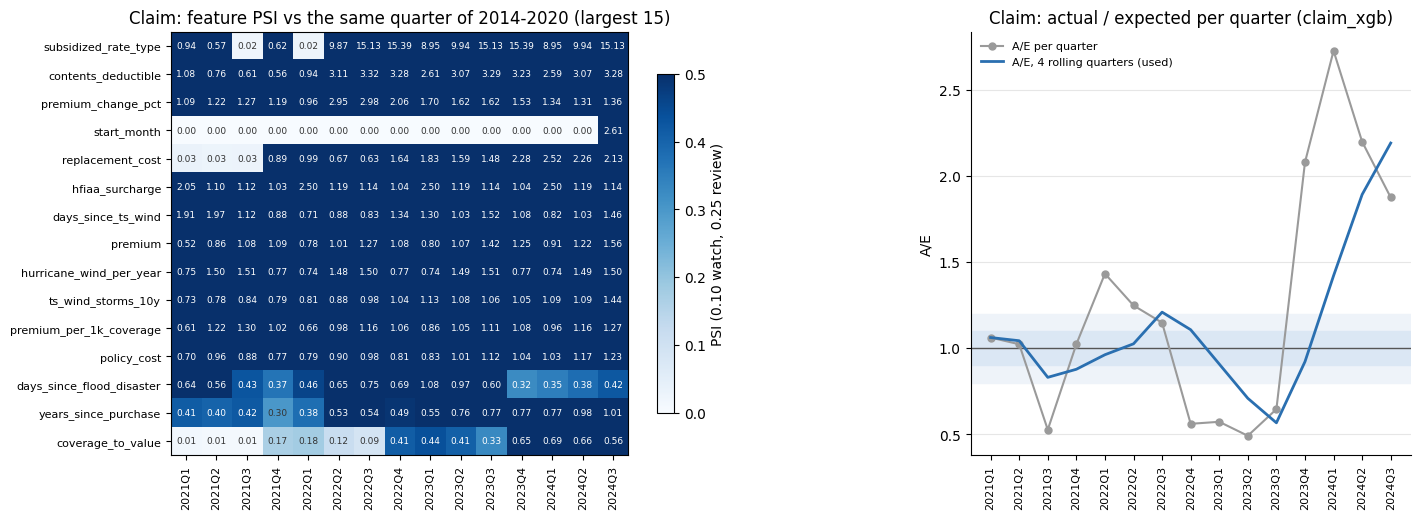

,quarter,score_psi,max_feature_psi,features_over_0.25,a_to_e,a_to_e_used,log_loss_skill,status,action
0,2021Q1,0.101,2.047,15,1.062,1.062,+26.05%,feature PSI > 0.25; score PSI watch,
1,2021Q2,0.107,1.966,14,1.023,1.043,+23.44%,feature PSI > 0.25; score PSI watch,
2,2021Q3,0.123,1.508,12,0.526,0.830,+10.10%,feature PSI > 0.25; score PSI watch; A/E watch,
3,2021Q4,0.146,1.194,14,1.023,0.877,-24.03%,feature PSI > 0.25; score PSI watch; A/E watch; skill < 0,
4,2022Q1,0.173,2.497,14,1.433,0.962,-24.45%,feature PSI > 0.25; score PSI watch; skill < 0,retrain
5,2022Q2,0.356,9.871,16,1.248,1.025,-15.00%,feature PSI > 0.25; score PSI > 0.25; skill < 0,retrain
6,2022Q3,0.353,15.126,16,1.148,1.209,+0.24%,feature PSI > 0.25; score PSI > 0.25; A/E outside 0.8-1.2,
7,2022Q4,0.274,15.393,19,0.560,1.107,+4.79%,feature PSI > 0.25; score PSI > 0.25; A/E watch,
8,2023Q1,0.266,8.954,18,0.572,0.908,+0.81%,feature PSI > 0.25; score PSI > 0.25,
9,2023Q2,0.197,9.944,20,0.491,0.709,+0.13%,feature PSI > 0.25; score PSI watch; A/E outside 0.8-1.2,


In [8]:
# Step 1.5 Claim: feature PSI, score PSI and A/E per quarter, and the alert rules
t0 = time.time()
monitor_claim, psi_claim = ev.monitor_quarters(con, "claim", registry["claim"], base_rate["claim"], KINDS, PRIMARY["claim"],
                                                 QUARTERS, REFERENCE_ROWS, QUARTER_ROWS, seed=SEED)
alerts_claim = ev.apply_alert_rules(monitor_claim, rolling_quarters=4)
print(f"{len(QUARTERS)} quarters in {(time.time() - t0) / 60:.1f} min")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
im = ev.plot_psi_heatmap(ax1, psi_claim, f"Claim: feature PSI vs the same quarter of 2014-2020 (largest 15)")
fig.colorbar(im, ax=ax1, shrink=0.8, label="PSI (0.10 watch, 0.25 review)")
x = np.arange(len(alerts_claim))
ax2.axhspan(0.8, 1.2, color="#eef3f9", zorder=0); ax2.axhspan(0.9, 1.1, color="#dbe7f4", zorder=0)
ax2.axhline(1, color="#555555", linewidth=1)
ax2.plot(x, alerts_claim["a_to_e"], color=ev.GREY, linewidth=1.5, marker="o", markersize=5, label="A/E per quarter")
if 4:
    ax2.plot(x, alerts_claim["a_to_e_used"], color="#2a6fb0", linewidth=2, label="A/E, 4 rolling quarters (used)")
ax2.set_xticks(x, alerts_claim["quarter"], rotation=90, fontsize=8)
ax2.set(title=f"Claim: actual / expected per quarter ({PRIMARY['claim']})", ylabel="A/E")
ax2.legend(frameon=False, fontsize=8)
ev.style_axes(ax2, grid="y")
plt.savefig(REPORTS / f"fig_{OUT}_claim_monitoring.png", dpi=150, bbox_inches="tight")
plt.show()
alerts_claim[["quarter", "score_psi", "max_feature_psi", "features_over_0.25", "a_to_e", "a_to_e_used", "log_loss_skill",
               "status", "action"]].style.format({"score_psi": "{:.3f}", "max_feature_psi": "{:.3f}", "a_to_e": "{:.3f}",
                                                   "a_to_e_used": "{:.3f}", "log_loss_skill": "{:+.2%}"})

### Section 2. Lapse model

#### 2.1 Probability check
The same measures as Step 1.1.

In [9]:
# Step 2.1 Lapse: log loss, Brier, skill and A/E, overall and per year
p = pred["lapse"]
prob_lapse = ev.probability_table([(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]], COLS["lapse"])
prob_lapse.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                          "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}",
                          "brier_skill": "{:+.2%}"})

,scope,model,rows,events,actual_rate,predicted_rate,a_to_e,log_loss,brier,log_loss_skill,brier_skill
0,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,621,274","578,846",10.297%,13.839%,0.744,0.33726,0.093625,+0.00%,+0.00%
1,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,621,274","578,846",10.297%,13.294%,0.775,0.33067,0.092330,+1.95%,+1.38%
2,"OOT2 (validation, 2023 - Aug 2024)",lapse_baseline_logreg,"5,621,274","578,846",10.297%,12.303%,0.837,0.33146,0.093275,+1.72%,+0.37%
3,"OOT2 (validation, 2023 - Aug 2024)",lapse_rf,"5,621,274","578,846",10.297%,13.019%,0.791,0.32520,0.091185,+3.58%,+2.61%
4,"OOT2 (validation, 2023 - Aug 2024)",lapse_xgb,"5,621,274","578,846",10.297%,11.848%,0.869,0.32697,0.091512,+3.05%,+2.26%
5,2023,base rate,"3,382,205","345,398",10.212%,13.839%,0.738,0.33571,0.093009,+0.00%,+0.00%
6,2023,segment rate,"3,382,205","345,398",10.212%,13.679%,0.747,0.33032,0.092113,+1.61%,+0.96%
7,2023,lapse_baseline_logreg,"3,382,205","345,398",10.212%,12.596%,0.811,0.33053,0.093063,+1.54%,-0.06%
8,2023,lapse_rf,"3,382,205","345,398",10.212%,13.094%,0.780,0.32242,0.090282,+3.96%,+2.93%
9,2023,lapse_xgb,"3,382,205","345,398",10.212%,12.064%,0.847,0.32529,0.090960,+3.10%,+2.20%


#### 2.2 Calibration
As in Step 1.2: deciles, ECE, intercept and slope, and expected vs actual lapses.

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warning

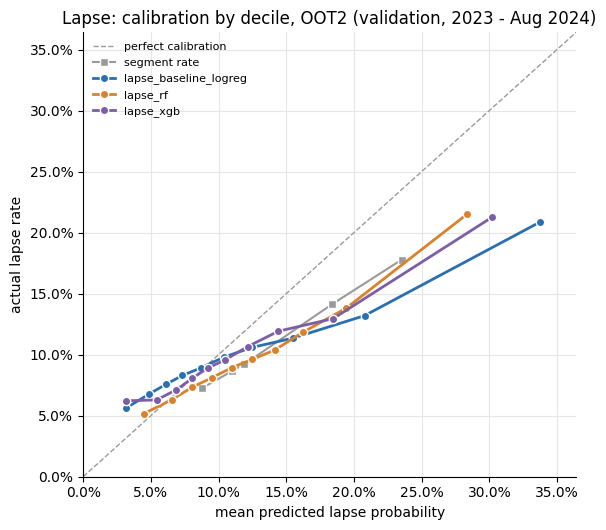

,actual,expected: base rate,expected: segment rate,expected: lapse_baseline_logreg,expected: lapse_rf,expected: lapse_xgb
period_year,,,,,,
2023,"345,398","468,072","462,667","426,015","442,873","408,020"
2024,"233,448","309,871","284,639","265,592","288,949","257,964"
all,"578,846","777,943","747,305","691,607","731,822","665,985"


,rows,events,predicted,actual,actual_to_predicted
p_lapse_rf,,,,,
10,"562,128","120,818",28.337%,21.493%,0.76
9,"562,127","77,591",19.419%,13.803%,0.71
8,"562,127","66,476",16.217%,11.826%,0.73
7,"562,128","58,326",14.143%,10.376%,0.73
6,"562,127","54,020",12.478%,9.610%,0.77
5,"562,127","50,248",10.989%,8.939%,0.81
4,"562,128","45,648",9.528%,8.121%,0.85
3,"562,127","41,230",8.055%,7.335%,0.91
2,"562,127","35,469",6.545%,6.310%,0.96


,model,a_to_e,ece,ece_pct_of_rate,intercept_a,slope_b
0,segment rate,0.775,0.02997,29.1%,-0.465,0.905
1,lapse_baseline_logreg,0.837,0.03403,33.0%,-1.066,0.533
2,lapse_rf,0.791,0.02859,27.8%,-0.639,0.795
3,lapse_xgb,0.869,0.02380,23.1%,-0.881,0.620


In [10]:
# Step 2.2 Lapse: calibration by decile, ECE, intercept and slope, and expected vs actual per year
calib_lapse, deciles_lapse = ev.calibration_summary(pred["lapse"], COLS["lapse"], seed=SEED)
fig, ax = plt.subplots(figsize=(6, 5.4))
ev.plot_calibration(ax, deciles_lapse, f"Lapse: calibration by decile, {EVAL_NAME}", "lapse")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_calibration.png", dpi=150)
plt.show()

p = pred["lapse"]
expected_lapse = p.groupby("period_year").agg(actual=("y", "sum"), **{f"expected: {n}": (c, "sum") for n, c in COLS["lapse"].items()})
expected_lapse.loc["all"] = expected_lapse.sum()
display(expected_lapse.style.format("{:,.0f}"))
display(deciles_lapse[PRIMARY["lapse"]].sort_index(ascending=False).style.format(
    {"rows": "{:,}", "events": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}", "actual_to_predicted": "{:.2f}"}))
calib_lapse.style.format({"a_to_e": "{:.3f}", "ece": "{:.5f}", "ece_pct_of_rate": "{:.1%}", "intercept_a": "{:+.3f}", "slope_b": "{:.3f}"})

#### 2.3 Calibration by segment
As in Step 1.3. For lapse, the storm segment shows whether policyholders hit by a storm during the term renewed more or less than the model expected.

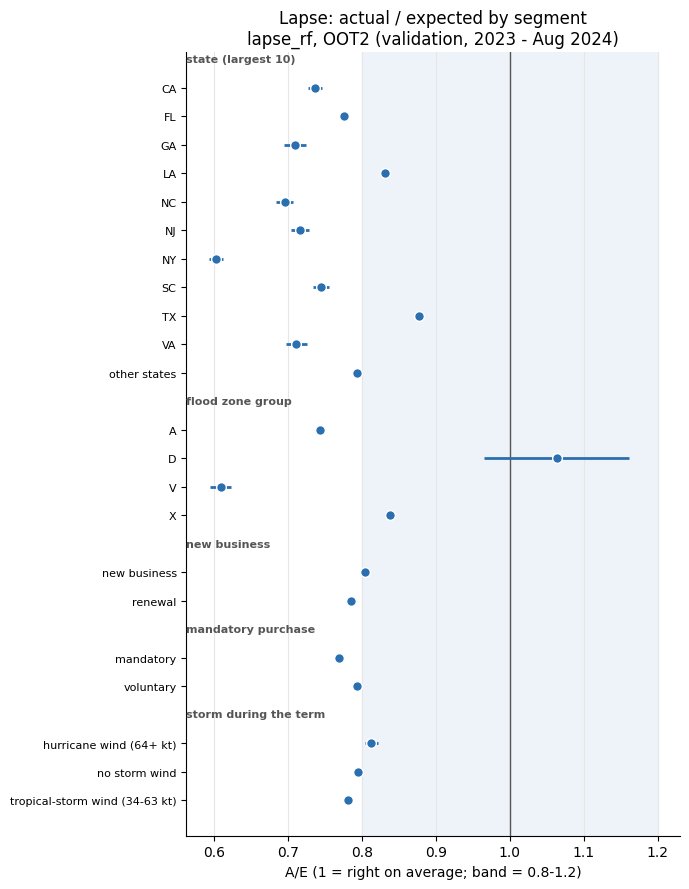

state (largest 10)


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,CA,base rate,"257,837","26,313",10.205%,0.737,+0.00%
1,CA,segment rate,"257,837","26,313",10.205%,0.768,+4.01%
2,CA,lapse_baseline_logreg,"257,837","26,313",10.205%,0.852,+4.81%
3,CA,lapse_rf,"257,837","26,313",10.205%,0.737,+6.35%
4,CA,lapse_xgb,"257,837","26,313",10.205%,0.833,+5.58%
5,FL,base rate,"1,668,156","172,360",10.332%,0.747,+0.00%
6,FL,segment rate,"1,668,156","172,360",10.332%,0.759,+1.64%
7,FL,lapse_baseline_logreg,"1,668,156","172,360",10.332%,0.746,-0.17%
8,FL,lapse_rf,"1,668,156","172,360",10.332%,0.777,+2.59%
9,FL,lapse_xgb,"1,668,156","172,360",10.332%,0.828,+2.42%


flood zone group


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,A,base rate,"2,978,053","251,182",8.434%,0.609,+0.00%
1,A,segment rate,"2,978,053","251,182",8.434%,0.641,+2.31%
2,A,lapse_baseline_logreg,"2,978,053","251,182",8.434%,0.745,+2.81%
3,A,lapse_rf,"2,978,053","251,182",8.434%,0.743,+5.18%
4,A,lapse_xgb,"2,978,053","251,182",8.434%,0.804,+4.81%
5,D,base rate,"2,473",456,18.439%,1.332,+0.00%
6,D,segment rate,"2,473",456,18.439%,1.192,+6.70%
7,D,lapse_baseline_logreg,"2,473",456,18.439%,0.974,+8.86%
8,D,lapse_rf,"2,473",456,18.439%,1.063,+11.08%
9,D,lapse_xgb,"2,473",456,18.439%,0.881,+8.83%


new business


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,new business,base rate,"881,880","157,071",17.811%,1.287,+0.00%
1,new business,segment rate,"881,880","157,071",17.811%,0.760,-0.72%
2,new business,lapse_baseline_logreg,"881,880","157,071",17.811%,0.651,-2.64%
3,new business,lapse_rf,"881,880","157,071",17.811%,0.805,+3.57%
4,new business,lapse_xgb,"881,880","157,071",17.811%,0.759,+1.50%
5,renewal,base rate,"4,739,394","421,775",8.899%,0.643,+0.00%
6,renewal,segment rate,"4,739,394","421,775",8.899%,0.780,+2.71%
7,renewal,lapse_baseline_logreg,"4,739,394","421,775",8.899%,0.936,+2.96%
8,renewal,lapse_rf,"4,739,394","421,775",8.899%,0.786,+3.58%
9,renewal,lapse_xgb,"4,739,394","421,775",8.899%,0.919,+3.49%


mandatory purchase


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,mandatory,base rate,"735,331","54,134",7.362%,0.532,+0.00%
1,mandatory,segment rate,"735,331","54,134",7.362%,0.833,+7.03%
2,mandatory,lapse_baseline_logreg,"735,331","54,134",7.362%,1.071,+6.67%
3,mandatory,lapse_rf,"735,331","54,134",7.362%,0.769,+7.24%
4,mandatory,lapse_xgb,"735,331","54,134",7.362%,0.954,+6.70%
5,voluntary,base rate,"4,885,943","524,712",10.739%,0.776,+0.00%
6,voluntary,segment rate,"4,885,943","524,712",10.739%,0.769,+1.33%
7,voluntary,lapse_baseline_logreg,"4,885,943","524,712",10.739%,0.819,+1.11%
8,voluntary,lapse_rf,"4,885,943","524,712",10.739%,0.793,+3.12%
9,voluntary,lapse_xgb,"4,885,943","524,712",10.739%,0.861,+2.60%


storm during the term


,segment,model,rows,events,actual_rate,a_to_e,log_loss_skill
0,hurricane wind (64+ kt),base rate,"279,687","31,484",11.257%,0.813,+0.00%
1,hurricane wind (64+ kt),segment rate,"279,687","31,484",11.257%,0.831,+1.47%
2,hurricane wind (64+ kt),lapse_baseline_logreg,"279,687","31,484",11.257%,0.771,-0.51%
3,hurricane wind (64+ kt),lapse_rf,"279,687","31,484",11.257%,0.813,+2.03%
4,hurricane wind (64+ kt),lapse_xgb,"279,687","31,484",11.257%,0.865,+2.07%
5,no storm wind,base rate,"3,300,615","341,096",10.334%,0.747,+0.00%
6,no storm wind,segment rate,"3,300,615","341,096",10.334%,0.773,+2.06%
7,no storm wind,lapse_baseline_logreg,"3,300,615","341,096",10.334%,0.868,+2.30%
8,no storm wind,lapse_rf,"3,300,615","341,096",10.334%,0.795,+3.91%
9,no storm wind,lapse_xgb,"3,300,615","341,096",10.334%,0.884,+3.27%


In [11]:
# Step 2.3 Lapse: A/E and skill by segment, for every model; chart for the primary model
seg_lapse = {label: ev.segment_table(pred["lapse"], COLS["lapse"], key(pred["lapse"])) for label, key in SEGMENTS.items()}
fig, ax = plt.subplots(figsize=(7, 9))
ev.plot_ae_by_segment(ax, seg_lapse, PRIMARY["lapse"], f"Lapse: actual / expected by segment\n{PRIMARY['lapse']}, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_segments.png", dpi=150)
plt.show()
for label, t in seg_lapse.items():
    print(label)
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss_skill": "{:+.2%}"}))

#### 2.4 Stability over time
As in Step 1.4. Lapse moves slowly, so a trend in the A/E is easier to see than for claims.

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

scored 11 years in 2.2 min


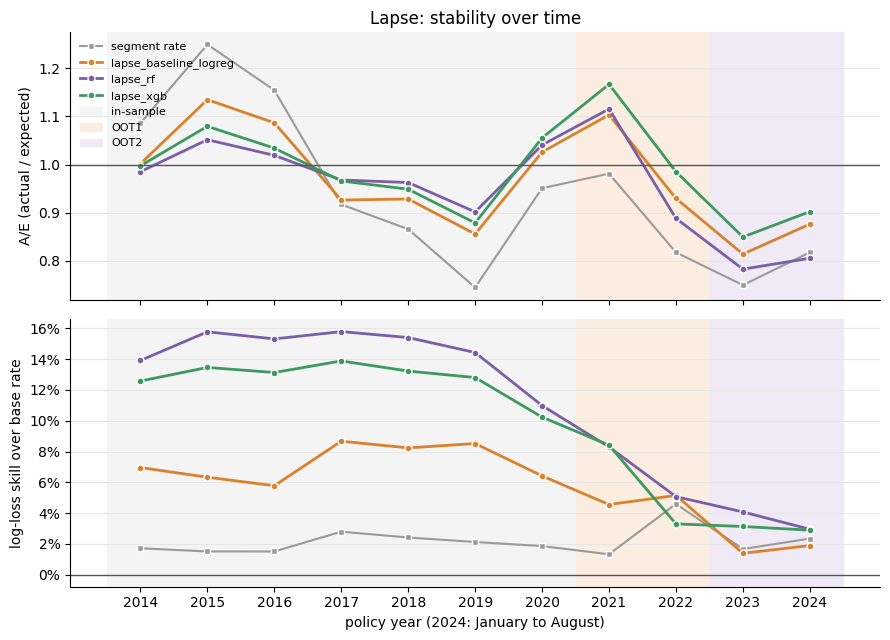

a_to_e                                           \
model          base rate lapse_baseline_logreg lapse_rf lapse_xgb   
year period                                                         
2014 in-sample     1.152                 1.001    0.985     0.997   
2015 in-sample     1.302                 1.135    1.052     1.079   
2016 in-sample     1.113                 1.087    1.019     1.034   
2017 in-sample     0.938                 0.926    0.968     0.966   
2018 in-sample     0.877                 0.928    0.963     0.949   
2019 in-sample     0.733                 0.856    0.902     0.879   
2020 in-sample     0.862                 1.026    1.041     1.055   
2021 OOT1          0.929                 1.103    1.115     1.167   
2022 OOT1          0.809                  0.93    0.888     0.985   
2023 OOT2          0.742                 0.814    0.783     0.849   
2024 OOT2          0.751                 0.876    0.805     0.902   

                            log_loss_skill                                 \
model          segment rate      base rate lapse_baseline_logreg lapse_rf   
year period                                                                 
2014 in-sample        1.086              0                  0.07    0.139   
2015 in-sample        1.249              0                 0.063    0.158   
2016 in-sample        1.155              0                 0.058    0.153   
2017 in-sample        0.917              0                 0.087    0.158   
2018 in-sample        0.866              0                 0.082    0.154   
2019 in-sample        0.745              0                 0.085    0.144   
2020 in-sample        0.951              0                 0.064     0.11   
2021 OOT1             0.981              0                 0.046    0.083   
2022 OOT1             0.817              0                 0.051    0.051   
2023 OOT2             0.749              0                 0.014    0.041   
2024 OOT2             0.817              0                 0.019    0.029   

                                       
model          lapse_xgb segment rate  
year period                            
2014 in-sample     0.126        0.017  
2015 in-sample     0.135        0.015  
2016 in-sample     0.131        0.015  
2017 in-sample     0.139        0.028  
2018 in-sample     0.132        0.024  
2019 in-sample     0.128        0.021  
2020 in-sample     0.102        0.019  
2021 OOT1          0.084        0.013  
2022 OOT1          0.033        0.046  
2023 OOT2          0.031        0.017  
2024 OOT2          0.029        0.023

In [12]:
# Step 2.4 Lapse: A/E and log-loss skill per year, 2014 to LAST_YEAR, on a sample of each year
t0 = time.time()
stability_lapse = ev.stability_by_year(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS,
                                        range(2014, LAST_YEAR + 1), STABILITY_ROWS, seed=SEED)
print(f"scored {stability_lapse['year'].nunique()} years in {(time.time() - t0) / 60:.1f} min")
fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ev.plot_by_year(axes, stability_lapse, COLS["lapse"], f"Lapse: stability over time")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_stability.png", dpi=150)
plt.show()
stability_lapse.pivot_table(index=["year", "period"], columns="model", values=["a_to_e", "log_loss_skill"]).round(3)

#### 2.5 Cohort survival analysis: retention of new business
Steps 2.1–2.4 judge the lapse model one policy-year at a time. An insurer also needs to know **how long a new policy stays**: of the policies sold in a year, how many are still in force after 1, 2, 3, … years? That is a **survival** (retention) curve, the insurance version of a cohort or flow-rate analysis.

**Cohort:** all policies that start as **new business** (tenure under one year, with no earlier policy-year on the same key) in the same calendar year. We follow a random sample of 30,000 policies per cohort through their later policy-years; year $k$ is the $k$-th policy-year since the policy was sold.

**Flow table (life table).** In each year $k$, policies at risk either lapse (flow out: a cancellation during the term or a non-renewal), renew into year $k+1$, or are **censored**: we stop seeing them without a lapse, because the data end or a later policy-year left the modeling population. A censored policy is not counted as a lapse.
$$h_k = \frac{\text{lapsed in year } k}{\text{at risk at the start of year } k} \qquad S(k) = \prod_{j=1}^{k}\big(1 - h_j\big)$$
$h_k$ is the **lapse hazard** (the flow rate out) and $S(k)$ the **survival**, the share of the cohort still in force after $k$ years (the Kaplan–Meier estimator for yearly steps).

**What the model predicts.** Our lapse model is a logistic regression on policy-years, which is a **discrete-time hazard model**: each prediction $p_{ik}$ is the probability that policy $i$ lapses in year $k$, given that it is still in force. Averaging over the same policies at risk gives the model's hazard and survival, directly comparable with the actual curve:
$$\hat h_k = \frac{1}{n_k}\sum_{i \,\in\, \text{at risk at } k} p_{ik} \qquad \hat S(k) = \prod_{j=1}^{k}\big(1 - \hat h_j\big)$$
A gap between $S(k)$ and $\hat S(k)$ that **grows with $k$** means the model's errors add up over the years, which matters for premium-income forecasts several years ahead.

**Limits:** only cohorts sold from 2014 onward (policies in force in 2014 were sold earlier: left truncation); later cohorts have shorter curves (a year is shown while at least 500 policies are at risk); only the first spell, up to the first lapse; nothing after 2022 is read in the dry run.

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

330,000 policies in 11 cohorts, 1,065,698 policy-years (0.6 min)


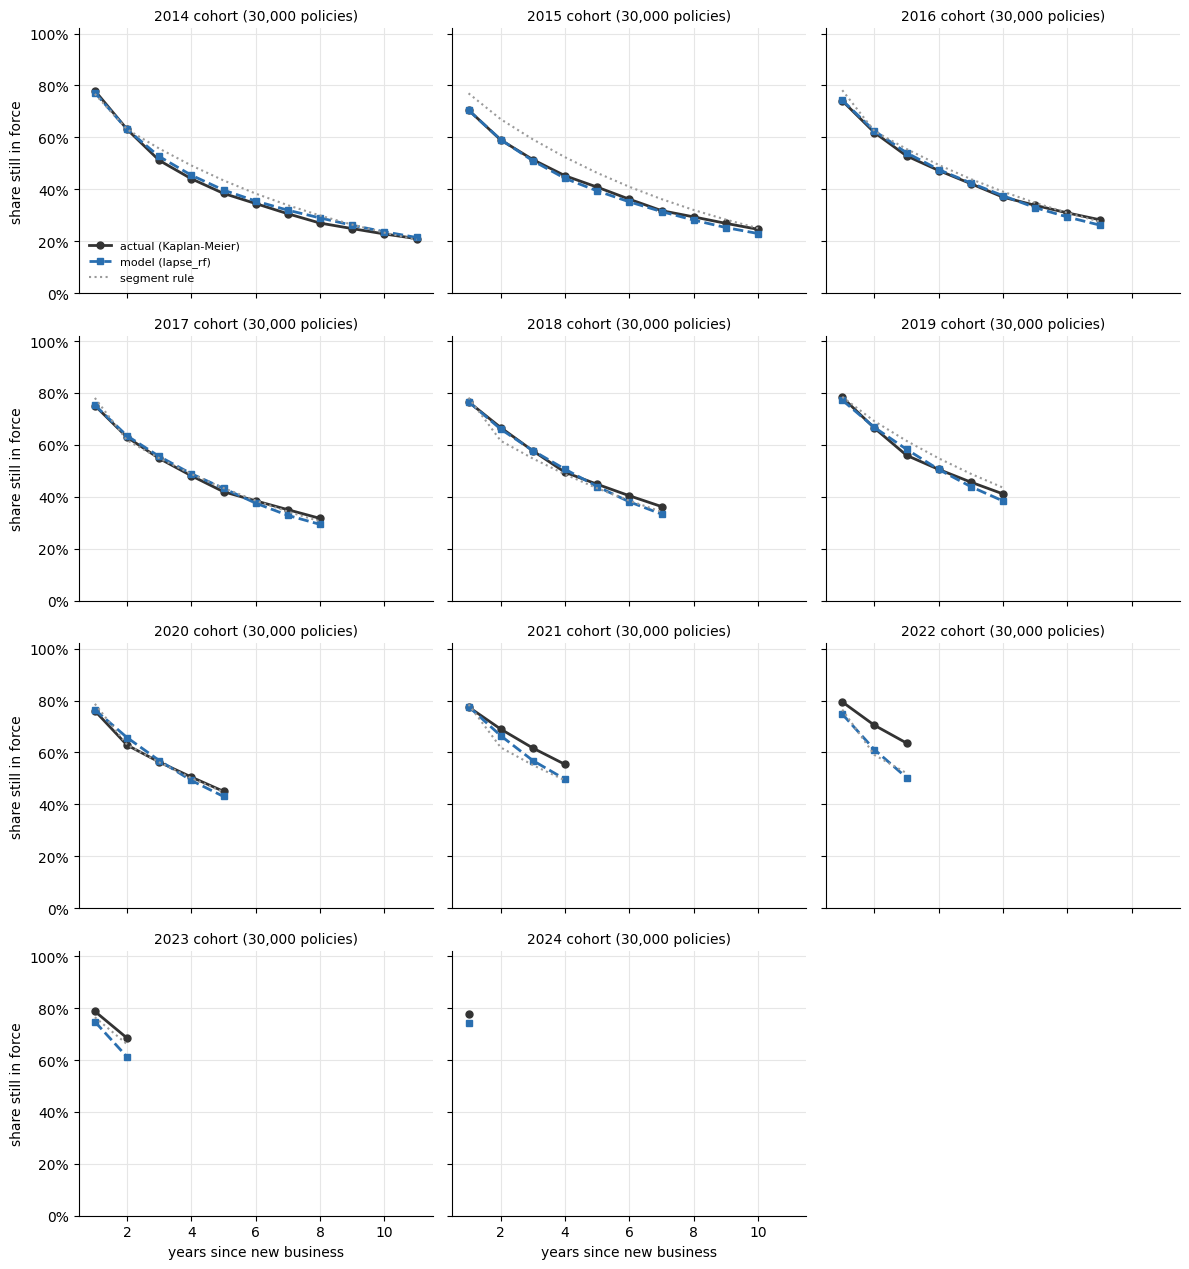

,at_risk,lapsed,cancelled,not_renewed,censored,hazard_actual,hazard_model,survival_actual,survival_model,survival_segment rule
year_k,,,,,,,,,,
1,"330,000","77,345","1,255","77,336","36,700",23.44%,24.61%,76.6%,75.4%,77.6%
2,"215,955","32,208",480,"32,202","25,759",14.91%,15.78%,65.1%,63.5%,63.3%
3,"157,988","21,045",292,"21,039","21,862",13.32%,14.02%,56.5%,54.6%,56.2%
4,"115,081","13,449",177,"13,445","17,613",11.69%,12.87%,49.9%,47.6%,49.9%
5,"84,019","9,088",125,"9,085","13,551",10.82%,12.11%,44.5%,41.8%,44.3%
6,"61,380","6,350",141,"6,347","11,950",10.35%,12.05%,39.9%,36.8%,39.4%
7,"43,080","4,396",85,"4,394","11,225",10.20%,11.56%,35.8%,32.5%,34.9%
8,"27,459","2,554",42,"2,554","7,078",9.30%,10.34%,32.5%,29.2%,31.0%
9,"17,827","1,477",43,"1,477","6,861",8.29%,10.16%,29.8%,26.2%,27.4%


,cohort,year_k,at_risk,survival_actual,survival_model,survival_segment rule,gap_model_pp,gap_segment_pp
0,2014,1,"30,000",78.0%,77.2%,76.7%,-0.7,-1.3
1,2014,2,"22,653",63.1%,63.1%,63.1%,-0.0,-0.0
2,2014,3,"17,745",51.1%,52.6%,55.7%,+1.5,+4.6
4,2014,5,"11,457",38.4%,39.7%,43.4%,+1.3,+5.0
11,2015,1,"30,000",70.5%,70.4%,77.0%,-0.1,+6.4
12,2015,2,"20,587",59.0%,59.1%,67.0%,+0.1,+8.0
13,2015,3,"16,647",51.4%,51.0%,59.2%,-0.5,+7.8
15,2015,5,"11,925",40.8%,39.4%,46.3%,-1.4,+5.5
21,2016,1,"30,000",74.1%,74.3%,78.2%,+0.2,+4.1
22,2016,2,"21,534",61.8%,62.5%,62.4%,+0.6,+0.6


In [13]:
# Step 2.5 New-business cohorts: actual vs predicted lapse hazard and survival, year by year
MIN_AT_RISK = 500
t0 = time.time()
cohort_years = ev.build_cohort_keys(con, LAST_YEAR, COHORT_KEYS, seed=SEED)
parts = [ev.score_rows(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS,
                       f"f.period_year <= {LAST_YEAR} AND f.policy_key IN (SELECT policy_key FROM cohort_keys WHERE cohort = {c})")[0]
         for c in cohort_years]
extra = con.sql(f"""
    SELECT f.period_id, CAST(f.CANCEL_IN_TERM AS INTEGER) AS cancelled, CAST(f.NON_RENEWAL AS INTEGER) AS not_renewed
    FROM feats f JOIN cohort_keys k USING (policy_key)
    WHERE f.in_pop_lapse AND f.period_year <= {LAST_YEAR}""").df()
cohort_rows = (pd.concat(parts, ignore_index=True)
                 .merge(con.sql("SELECT * FROM cohort_keys").df(), on="policy_key")
                 .merge(extra, on="period_id", how="left"))
del parts

# Year since new business, and only the first spell (up to and including the first lapse)
cohort_rows = cohort_rows[cohort_rows["period_start"] >= cohort_rows["entry_start"]].sort_values(["policy_key", "period_start"])
cohort_rows["year_k"] = cohort_rows.groupby("policy_key").cumcount() + 1
cohort_rows = cohort_rows[cohort_rows.groupby("policy_key")["y"].cumsum() - cohort_rows["y"] == 0]
print(f"{cohort_rows['policy_key'].nunique():,} policies in {len(cohort_years)} cohorts, {len(cohort_rows):,} policy-years "
      f"({(time.time() - t0) / 60:.1f} min)")

CURVES = {"model": f"p_{PRIMARY['lapse']}", "segment rule": "p_segment"}
tables = {c: ev.life_table(g, CURVES, MIN_AT_RISK) for c, g in cohort_rows.groupby("cohort")}
tables["all cohorts"] = ev.life_table(cohort_rows, CURVES, MIN_AT_RISK)
cohort_tables = pd.concat(tables, names=["cohort"]).reset_index()
cohort_check = cohort_tables[cohort_tables["year_k"].isin([1, 2, 3, 5])].assign(
    gap_model_pp=lambda t: 100 * (t["survival_model"] - t["survival_actual"]),
    gap_segment_pp=lambda t: 100 * (t["survival_segment rule"] - t["survival_actual"]))[
    ["cohort", "year_k", "at_risk", "survival_actual", "survival_model", "survival_segment rule", "gap_model_pp", "gap_segment_pp"]]

# One panel per cohort: actual vs predicted survival
ncols = 3
nrows = int(np.ceil(len(cohort_years) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows), sharex=True, sharey=True, squeeze=False)
for ax, c in zip(axes.ravel(), cohort_years):
    t = tables[c]
    ax.plot(t.index, t["survival_actual"], color="#333333", linewidth=2, marker="o", markersize=5, label="actual (Kaplan-Meier)")
    ax.plot(t.index, t["survival_model"], color="#2a6fb0", linewidth=2, linestyle="--", marker="s", markersize=4,
            label=f"model ({PRIMARY['lapse']})")
    ax.plot(t.index, t["survival_segment rule"], color=ev.GREY, linewidth=1.5, linestyle=":", label="segment rule")
    ax.set_title(f"{c} cohort ({t['at_risk'].iloc[0]:,} policies)", fontsize=10)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ev.style_axes(ax)
for ax in axes.ravel()[len(cohort_years):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("years since new business")
for ax in axes[:, 0]:
    ax.set_ylabel("share still in force")
axes[0, 0].set_ylim(0, 1.02)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_cohort_survival.png", dpi=150)
plt.show()

display(tables["all cohorts"][["at_risk", "lapsed", "cancelled", "not_renewed", "censored", "hazard_actual", "hazard_model",
                               "survival_actual", "survival_model", "survival_segment rule"]].style.format(
    {"at_risk": "{:,}", "lapsed": "{:,}", "cancelled": "{:,}", "not_renewed": "{:,}", "censored": "{:,}",
     "hazard_actual": "{:.2%}", "hazard_model": "{:.2%}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}",
     "survival_segment rule": "{:.1%}"}))
cohort_check.style.format({"at_risk": "{:,}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}",
                           "survival_segment rule": "{:.1%}", "gap_model_pp": "{:+.1f}", "gap_segment_pp": "{:+.1f}"})

#### 2.6 Retention by segment at sale
The same curves for groups defined **at the time of sale**, pooling all cohorts: mandatory vs voluntary purchase (a lender's requirement should keep policies in force), and the flood zone group. The solid line is the actual retention, the dashed line the model's.

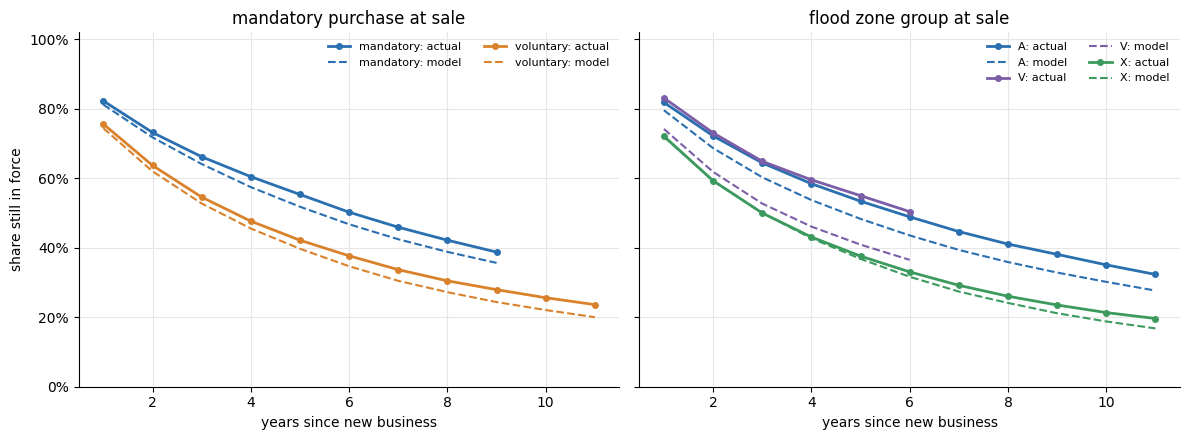

,segment_type,segment,year_k,at_risk,survival_actual,survival_model
0,mandatory purchase at sale,mandatory,1,"47,782",82.3%,81.2%
1,mandatory purchase at sale,mandatory,2,"38,327",73.2%,71.8%
2,mandatory purchase at sale,mandatory,3,"33,117",66.2%,64.1%
4,mandatory purchase at sale,mandatory,5,"19,189",55.3%,51.8%
9,mandatory purchase at sale,voluntary,1,"282,218",75.6%,74.4%
10,mandatory purchase at sale,voluntary,2,"177,628",63.7%,62.0%
11,mandatory purchase at sale,voluntary,3,"124,871",54.6%,52.8%
13,mandatory purchase at sale,voluntary,5,"64,830",42.2%,39.7%
20,flood zone group at sale,A,1,"147,492",81.8%,79.6%
21,flood zone group at sale,A,2,"100,236",72.2%,68.7%


In [14]:
# Step 2.6 Actual vs predicted retention by segment at the time of sale (all cohorts pooled)
at_sale = cohort_rows.sort_values("year_k").groupby("policy_key")[["mandatory_purchase", "zone_group"]].first()
seg_rows = cohort_rows.drop(columns=["mandatory_purchase", "zone_group"]).join(at_sale, on="policy_key")
SEG_AT_SALE = {"mandatory purchase at sale": seg_rows["mandatory_purchase"].map({1: "mandatory", 0: "voluntary"}),
               "flood zone group at sale": seg_rows["zone_group"].astype("string").fillna("(missing)")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
retention_tables = {}
for ax, (label, key) in zip(axes, SEG_AT_SALE.items()):
    for i, (g, part) in enumerate(seg_rows.groupby(key)):
        t = ev.life_table(part, CURVES, MIN_AT_RISK)
        if t.empty:
            continue
        retention_tables[(label, g)] = t
        color = ev.MODEL_COLORS[i % len(ev.MODEL_COLORS)]
        ax.plot(t.index, t["survival_actual"], color=color, linewidth=2, marker="o", markersize=4, label=f"{g}: actual")
        ax.plot(t.index, t["survival_model"], color=color, linewidth=1.5, linestyle="--", label=f"{g}: model")
    ax.set(title=label, xlabel="years since new business", ylim=(0, 1.02))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.legend(frameon=False, fontsize=8, ncol=2)
    ev.style_axes(ax)
axes[0].set_ylabel("share still in force")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_cohort_segments.png", dpi=150)
plt.show()
(pd.concat(retention_tables, names=["segment_type", "segment"]).reset_index()
   .query("year_k in [1, 2, 3, 5]")[["segment_type", "segment", "year_k", "at_risk", "survival_actual", "survival_model"]]
   .style.format({"at_risk": "{:,}", "survival_actual": "{:.1%}", "survival_model": "{:.1%}"}))

#### Our findings (Steps 2.5–2.6, final run)

Primary lapse model: the random forest (`lapse_rf`). 330,000 new policies in 11 cohorts (2014–2024), 1,065,698 policy-years.

**2.5 Retention of new business**

1. **A new flood policy has a short life.** Pooling every cohort, **23% of new policies lapse in their first year**; 65% are still in force after two years, 56% after three and **44% after five**. The lapse hazard is highest in year 1 (23.4%), falls to 14.9% in year 2 and settles at about 8–12% a year from year 4. The **first renewal** is the main point of loss.
2. **Almost every lapse is a non-renewal.** In year 1, 77,336 of the 77,345 lapses were non-renewals and only 1,255 policies were cancelled during the term (a policy can carry both flags). Retention work should focus on the **renewal date**.
3. **The model follows retention closely for the 2014–2020 cohorts**: within about **±2–3 percentage points** in each of the first five years (for example, 2017 cohort after year 5: 41.9% actual, 43.3% predicted). Pooled over all cohorts the model is slightly pessimistic, and the gap grows slowly with age (−1.2 points after year 1, −2.7 after year 5), because the recent cohorts pull it down (next point). The segment rule fits the pooled curve almost exactly but misses individual cohorts by much more (2015 cohort: +6 to +8 points every year).
4. **Recent customers stay longer than the model expects.** For the **2021–2024 cohorts**, actual retention is above the prediction, and the gap widens with each year:
   - 2022 cohort: 79.5% actual vs 74.8% predicted after year 1, 70.5% vs 61.1% after year 2, **63.6% vs 50.3% after year 3**;
   - 2023 cohort: 78.7% vs 74.8% after year 1, 68.5% vs 61.2% after year 2.

   These years follow **Risk Rating 2.0** (April 2022): premiums and the price features changed sharply (Step 2.7), and the model reads the new prices as higher lapse risk, but fewer policyholders left than in the training years.

**2.6 Retention by segment at sale**

5. **Mandatory purchase keeps policies in force:** 55.3% of mandatory-purchase policies are still in force after five years, against 42.2% of voluntary ones. The model is 1–3.5 points too pessimistic for both.
6. **Flood zone matters most.** After five years, 53.4% of zone A policies and 55.0% of zone V policies are still in force, against 37.6% in zone X (lower risk, rarely required by a lender). The model is right for **zone X** (within 1 point every year) but **too pessimistic for the high-risk zones**: zone A 48.3% predicted vs 53.4% actual after year 5, and **zone V 40.9% vs 55.0%** (a small group: 3,985 policies at sale).

#### 2.7 Simulated monitoring
As in Step 1.5, with the quarterly A/E rule (lapse moves slowly, so no rolling window).

/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

15 quarters in 3.5 min


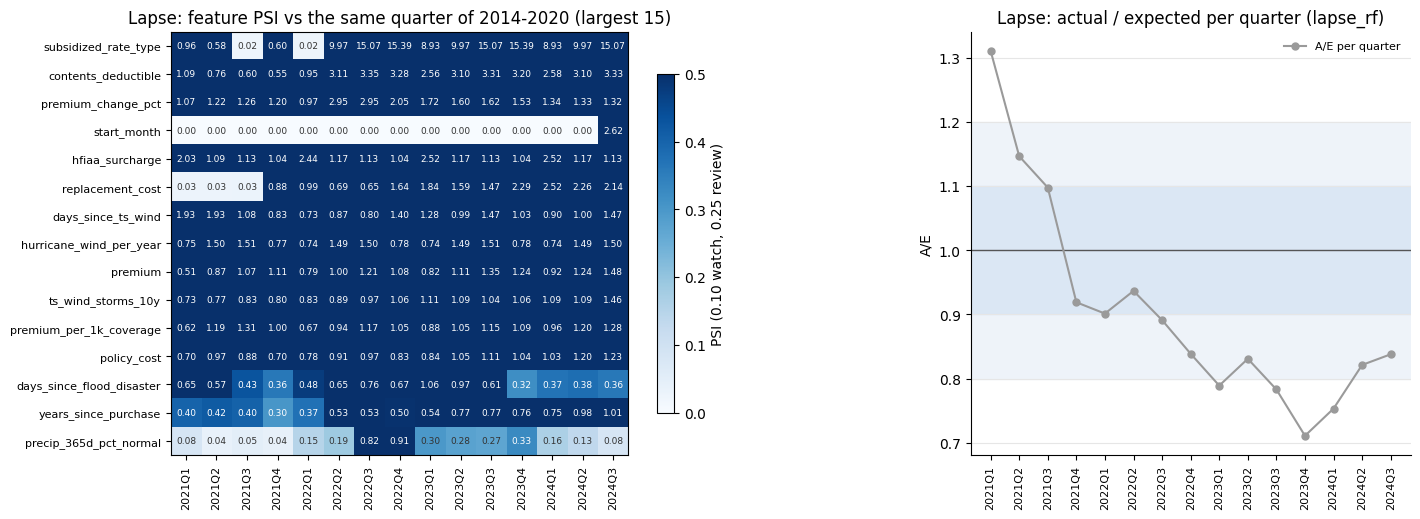

,quarter,score_psi,max_feature_psi,features_over_0.25,a_to_e,a_to_e_used,log_loss_skill,status,action
0,2021Q1,0.160,2.025,15,1.311,1.311,+8.73%,feature PSI > 0.25; score PSI watch; A/E outside 0.8-1.2,
1,2021Q2,0.151,1.929,14,1.147,1.147,+8.07%,feature PSI > 0.25; score PSI watch; A/E watch,
2,2021Q3,0.180,1.514,12,1.098,1.098,+8.75%,feature PSI > 0.25; score PSI watch,
3,2021Q4,0.183,1.195,14,0.919,0.919,+7.08%,feature PSI > 0.25; score PSI watch,
4,2022Q1,0.124,2.445,15,0.901,0.901,+6.11%,feature PSI > 0.25; score PSI watch,
5,2022Q2,0.255,9.967,16,0.937,0.937,+4.98%,feature PSI > 0.25; score PSI > 0.25,
6,2022Q3,0.295,15.073,18,0.891,0.891,+5.19%,feature PSI > 0.25; score PSI > 0.25; A/E watch,
7,2022Q4,0.193,15.387,19,0.839,0.839,+4.08%,feature PSI > 0.25; score PSI watch; A/E watch,
8,2023Q1,0.178,8.930,19,0.789,0.789,+3.75%,feature PSI > 0.25; score PSI watch; A/E outside 0.8-1.2,
9,2023Q2,0.204,9.967,21,0.831,0.831,+5.42%,feature PSI > 0.25; score PSI watch; A/E watch,


In [15]:
# Step 2.7 Lapse: feature PSI, score PSI and A/E per quarter, and the alert rules
t0 = time.time()
monitor_lapse, psi_lapse = ev.monitor_quarters(con, "lapse", registry["lapse"], base_rate["lapse"], KINDS, PRIMARY["lapse"],
                                                 QUARTERS, REFERENCE_ROWS, QUARTER_ROWS, seed=SEED)
alerts_lapse = ev.apply_alert_rules(monitor_lapse, rolling_quarters=None)
print(f"{len(QUARTERS)} quarters in {(time.time() - t0) / 60:.1f} min")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.45})
im = ev.plot_psi_heatmap(ax1, psi_lapse, f"Lapse: feature PSI vs the same quarter of 2014-2020 (largest 15)")
fig.colorbar(im, ax=ax1, shrink=0.8, label="PSI (0.10 watch, 0.25 review)")
x = np.arange(len(alerts_lapse))
ax2.axhspan(0.8, 1.2, color="#eef3f9", zorder=0); ax2.axhspan(0.9, 1.1, color="#dbe7f4", zorder=0)
ax2.axhline(1, color="#555555", linewidth=1)
ax2.plot(x, alerts_lapse["a_to_e"], color=ev.GREY, linewidth=1.5, marker="o", markersize=5, label="A/E per quarter")
if None:
    ax2.plot(x, alerts_lapse["a_to_e_used"], color="#2a6fb0", linewidth=2, label="A/E, 4 rolling quarters (used)")
ax2.set_xticks(x, alerts_lapse["quarter"], rotation=90, fontsize=8)
ax2.set(title=f"Lapse: actual / expected per quarter ({PRIMARY['lapse']})", ylabel="A/E")
ax2.legend(frameon=False, fontsize=8)
ev.style_axes(ax2, grid="y")
plt.savefig(REPORTS / f"fig_{OUT}_lapse_monitoring.png", dpi=150, bbox_inches="tight")
plt.show()
alerts_lapse[["quarter", "score_psi", "max_feature_psi", "features_over_0.25", "a_to_e", "a_to_e_used", "log_loss_skill",
               "status", "action"]].style.format({"score_psi": "{:.3f}", "max_feature_psi": "{:.3f}", "a_to_e": "{:.3f}",
                                                   "a_to_e_used": "{:.3f}", "log_loss_skill": "{:+.2%}"})

### Section 3. Appendix: extra checks
Two checks that do not change the results but tell us how much to trust them, for both targets.

#### 3.1 Bootstrap by policy: is the gain over the benchmarks real?
We put a 95% interval on the **difference** in log loss between the primary model and each other model, on the same rows:
$$\Delta = \overline{\ell}_{\text{other}} - \overline{\ell}_{\text{primary}}, \qquad \ell_i = -\big[y_i\log p_i + (1-y_i)\log(1-p_i)\big]$$
$\Delta > 0$ means the primary model is better. Policy-years of the same policy are not independent, so we **resample policies, not rows**: each bootstrap sample gives every policy a random weight $w_k \sim \text{Poisson}(1)$, and $\Delta^{*} = \sum_k w_k D_k / \sum_k w_k n_k$, where $D_k$ is the sum of the differences over policy $k$'s rows and $n_k$ its number of rows. The 2.5th and 97.5th percentiles of 200 samples give the interval; an interval that does not include 0 means the gain is real for this period.

In [16]:
# Step 3.1 Paired bootstrap of the log-loss difference, resampling policies (Poisson bootstrap)
bootstrap = pd.concat({kind: ev.bootstrap_log_loss(pred[kind], COLS[kind], f"p_{PRIMARY[kind]}", n_boot=N_BOOT, seed=SEED)
                       for kind in ev.TARGETS}, names=["target"]).reset_index(level=0)
bootstrap.style.format({"policies": "{:,}", "difference": "{:+.6f}", "ci_low": "{:+.6f}", "ci_high": "{:+.6f}"})

,target,compared_with,policies,difference,ci_low,ci_high,primary_better
0,claim,base rate,"3,680,332",-0.001483,-0.001614,-0.001370,no
1,claim,segment rate,"3,680,332",-0.004104,-0.004238,-0.003981,no
2,claim,claim_baseline_logreg,"3,680,332",-0.003911,-0.004044,-0.003791,no
3,claim,claim_lgbm,"3,680,332",-0.002359,-0.002443,-0.002280,no
4,claim,claim_rf,"3,680,332",-0.006139,-0.006259,-0.006015,no
0,lapse,base rate,"3,614,311",+0.012063,+0.011901,+0.012205,yes
1,lapse,segment rate,"3,614,311",+0.005470,+0.005325,+0.005581,yes
2,lapse,lapse_baseline_logreg,"3,614,311",+0.006253,+0.006131,+0.006395,yes
3,lapse,lapse_xgb,"3,614,311",+0.001768,+0.001671,+0.001862,yes


#### 3.2 Sensitivity to policy history and linkage
FEMA's data have no policy number, so notebook 03 rebuilt each policy's history with a policy key. Key collisions (5.2% of policy-years) were already excluded in notebook 04. What remains uncertain is the history of the policies we kept, so we compare the models on three kinds of history:

| History | Meaning | Why it matters |
|---|---|---|
| Continuous renewal | the previous term ended right before this one | the most reliable link |
| Returned after a gap | the key came back after a lapse | the link across the gap is less certain |
| First term on the key | no earlier term found | new business, or a link that was missed |

If the A/E or the skill is much worse for the last two, part of the error comes from linkage rather than from the model. We also show how the claims of the evaluation years were matched to terms (notebook 03).

In [17]:
# Step 3.2 Claim-match quality in the evaluation years, and the models by policy history
match = con.sql(f"""
    SELECT match_status, COUNT(*) AS claims
    FROM read_parquet('{PROCESSED / 'claim_links' / '*.parquet'}')
    WHERE loss_year BETWEEN {2021 if EVAL_SPLIT == 'test' else 2023} AND {LAST_YEAR}
    GROUP BY ALL ORDER BY claims DESC""").df()
match["share"] = match["claims"] / match["claims"].sum()
display(match.style.format({"claims": "{:,}", "share": "{:.2%}"}))
history = {kind: ev.segment_table(pred[kind], COLS[kind], pred[kind]["history"]) for kind in ev.TARGETS}
for kind, t in history.items():
    print(f"{kind}: by policy history")
    display(t[["segment", "model", "rows", "events", "actual_rate", "a_to_e", "log_loss", "log_loss_skill"]].style.format(
        {"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "a_to_e": "{:.3f}", "log_loss": "{:.5f}", "log_loss_skill": "{:+.2%}"}))

,match_status,claims,share
0,matched,"111,214",89.99%
1,matched_multi,"9,996",8.09%
2,key_incomplete,"1,794",1.45%
3,outside_term,398,0.32%
4,key_not_found,176,0.14%


claim: by policy history


,segment,model,rows,events,actual_rate,a_to_e,log_loss,log_loss_skill
0,continuous renewal,base rate,"5,113,183","76,577",1.498%,1.151,0.07793,+0.00%
1,continuous renewal,segment rate,"5,113,183","76,577",1.498%,1.106,0.07518,+3.53%
2,continuous renewal,claim_baseline_logreg,"5,113,183","76,577",1.498%,0.871,0.07526,+3.43%
3,continuous renewal,claim_lgbm,"5,113,183","76,577",1.498%,1.104,0.07701,+1.18%
4,continuous renewal,claim_rf,"5,113,183","76,577",1.498%,0.873,0.07352,+5.66%
5,continuous renewal,claim_xgb,"5,113,183","76,577",1.498%,1.368,0.07901,-1.40%
6,first term on the key,base rate,"610,860","12,926",2.116%,1.626,0.10470,+0.00%
7,first term on the key,segment rate,"610,860","12,926",2.116%,1.775,0.10316,+1.47%
8,first term on the key,claim_baseline_logreg,"610,860","12,926",2.116%,1.241,0.10431,+0.37%
9,first term on the key,claim_lgbm,"610,860","12,926",2.116%,1.886,0.10420,+0.47%


lapse: by policy history


,segment,model,rows,events,actual_rate,a_to_e,log_loss,log_loss_skill
0,continuous renewal,base rate,"5,022,839","458,755",9.133%,0.660,0.31598,+0.00%
1,continuous renewal,segment rate,"5,022,839","458,755",9.133%,0.747,0.31075,+1.65%
2,continuous renewal,lapse_baseline_logreg,"5,022,839","458,755",9.133%,0.885,0.30977,+1.97%
3,continuous renewal,lapse_rf,"5,022,839","458,755",9.133%,0.775,0.30607,+3.13%
4,continuous renewal,lapse_xgb,"5,022,839","458,755",9.133%,0.892,0.30727,+2.75%
5,first term on the key,base rate,"597,710","119,994",20.076%,1.451,0.51608,+0.00%
6,first term on the key,segment rate,"597,710","119,994",20.076%,0.903,0.49798,+3.51%
7,first term on the key,lapse_baseline_logreg,"597,710","119,994",20.076%,0.694,0.51350,+0.50%
8,first term on the key,lapse_rf,"597,710","119,994",20.076%,0.861,0.48577,+5.87%
9,first term on the key,lapse_xgb,"597,710","119,994",20.076%,0.794,0.49223,+4.62%


### Section 4. Conclusions and save

#### 4.1 Our findings (final run: validation, OOT2 = policy-years 2023 – Aug 2024)

Primary models: XGBoost for claims (`claim_xgb`), the random forest for lapse (`lapse_rf`), both chosen on the test years before the holdout was opened. A/E = actual ÷ expected events (1.0 = right on average; above 1 = the model predicts too few).

**Claim model**

1. **Probability check (Step 1.1):** on 2023–24 the **random forest has the best log loss** (skill **+5.8%** over the base rate), ahead of the segment rule (+3.2%), the logistic regression (+3.0%) and LightGBM (+1.1%). **XGBoost, the primary model, is worse than the base rate (−1.8%)**, and the bootstrap (Step 3.1) confirms it is worse than every other model and benchmark (all intervals below zero). XGBoost ranks claims well (08a) but its scores **should not be used as probabilities**.
2. **Calibration (Step 1.2):** over both years the logistic regression and the random forest are close on average (A/E 0.91 and 0.92) and their calibration slope is about 1 (0.97): their probabilities spread about right. XGBoost and LightGBM predict too few claims (A/E 1.43 and 1.17) and are over-confident (slope 0.48 and 0.54).
3. **Claims follow storms the models can't see (Steps 1.3, 1.4):** policy-years hit by **hurricane-force wind during the term** claimed at **9.8%**, against 0.6% with no storm wind, while the models predicted about 1–2% for both (A/E 5.5–12.4 for the hurricane group, 0.35–0.56 for the calm group). Whether a storm hits is unknown at the start of the policy, so no start-of-policy model can capture it. This drives the **year-to-year swings**: every model over-predicts **2023** (A/E 0.58–0.90: 33,302 claims against about 57,000 expected by the logistic regression and the random forest) and under-predicts **2024** (A/E 1.37–2.20: 56,214 claims against about 41,000 expected), whose policy-years were in force during Hurricanes Helene and Milton (Sept–Oct 2024). The same pattern runs through the earlier years: the logistic regression's A/E ranges from 0.53 (2014) to 1.85 (2017).
4. **Monitoring (Step 1.5):** the quarterly A/E of the primary model moves from **0.49–0.65 in 2023 Q1–Q3 to 1.9–2.7 in 2023 Q4 – 2024 Q3**; the alert rules call for recalibration (2023 Q3, 2024 Q2) and retraining (2024 Q3). This reflects storm activity more than a broken model, but it shows that expected claims need a **storm or catastrophe overlay**, not the model alone.

**Lapse model**

5. **Probability check (Step 2.1):** the **random forest has the best log loss** in 2023–24 (skill +3.6%), ahead of XGBoost (+3.1%), the segment rule (+2.0%) and the logistic regression (+1.7%). The bootstrap shows the gain is real against every model and benchmark, though small against XGBoost (0.0018).
6. **Calibration (Step 2.2): every model over-predicts lapse.** The random forest expects 731,822 lapses against **578,846 actual** (A/E 0.79); the logistic regression 0.84 and XGBoost 0.87. The lapse rate fell from 13.8% (train) to 10.3% (validation), and the models still carry the old level. The random forest's slope (0.80) is closer to 1 than the logistic regression's (0.53), so its probabilities are spread more realistically.
7. **Segments and history (Step 2.3, 3.2):** the over-prediction is broad (continuous renewals: A/E 0.77 for the random forest). First-term policies lapse at 20.1%, and the random forest is the closest on them (A/E 0.86). The 725 policies that returned after a gap are badly over-predicted by every model (A/E 0.37–0.45), but they are too few to matter overall.
8. **Stability and monitoring (Steps 2.4, 2.7):** in the training years the random forest's A/E stays between 0.90 and 1.05; after 2021 (1.12) it drops to 0.89 in 2022 and **0.78–0.81 in 2023–24**, and the quarterly A/E stays below 0.8 for most of 2023–24 (recalibration alerts in 2023 Q4 and 2024 Q1). The **price features shift sharply from 2022 Q2**: `subsidized_rate_type` (PSI 9–15), `premium_change_pct` (about 3), `premium` and `policy_cost` (about 1). This matches **Risk Rating 2.0** (April 2022): the link between price and lapse learned on 2014–2020 no longer fully holds.
9. **Cohort survival (Steps 2.5–2.6):** the model follows the retention of the 2014–2020 cohorts within about ±2–3 points, but the 2021–2024 cohorts stay longer than predicted (2022 cohort after three years: 63.6% actual vs 50.3% predicted), and it is too pessimistic for zones A and V (see the findings above Step 2.7).

**Recommendation**

10. **Lapse:** use the **random forest**. Before production, **recalibrate** it on recent years (for example, isotonic or Platt on 2021–2023), which fixes the expected lapses and premium at risk without changing who is on the list; set the retention list as **the riskiest 20% of each year's renewals** rather than a fixed 2014–2020 cut-off; then **refit on 2014–2023** so the model learns the post-Risk Rating 2.0 behaviour.
11. **Claims:** for **ranking** (underwriting review lists), a tree model; for **probabilities** (expected claims), the **random forest or the logistic regression**, not XGBoost. In both cases expected claims need a **storm overlay** (for example, scenario or catastrophe-model adjustments by season), because storms during the term drive most of the year-to-year change.
12. **Monitoring:** keep the quarterly checks of Steps 1.5 and 2.7 (score and feature PSI against the same calendar quarter, A/E with a 4-quarter rolling window for claims). Both models already trigger their recalibration or retraining rules in 2023–24.

#### 4.2 Save the results
Every table goes to `reports/` with the prefix `eval_test_` (dry run) or `eval_valid_` (final run), next to the charts saved above.

In [18]:
# Step 4.2 Save the tables of 08b
for kind in ev.TARGETS:
    g = globals()
    g[f"prob_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_probability.csv", index=False)
    g[f"calib_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_calibration_summary.csv", index=False)
    pd.concat(g[f"deciles_{kind}"], names=["model", "decile"]).to_csv(REPORTS / f"{OUT}_{kind}_calibration_deciles.csv")
    g[f"expected_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_expected_vs_actual.csv")
    pd.concat(g[f"seg_{kind}"], names=["segment_type"]).to_csv(REPORTS / f"{OUT}_{kind}_by_segment.csv")
    g[f"stability_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_stability_by_year.csv", index=False)
    g[f"alerts_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_monitoring.csv", index=False)
    g[f"psi_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_feature_psi.csv")
    history[kind].to_csv(REPORTS / f"{OUT}_{kind}_by_history.csv", index=False)
cohort_tables.to_csv(REPORTS / f"{OUT}_lapse_cohort_life_tables.csv", index=False)
cohort_check.to_csv(REPORTS / f"{OUT}_lapse_cohort_check.csv", index=False)
bootstrap.to_csv(REPORTS / f"{OUT}_bootstrap.csv", index=False)
print(f"saved {OUT}_* tables and charts to {REPORTS}")

saved eval_valid_* tables and charts to /Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/reports
